# Лабораторная работа №3. Кластеризация категориальных данных. CLOPE

**Цель:** разбить животных с номинальными признаками методом CLOPE, сравнить разбиение с k-modes на расстоянии Гауэра и прочитать оба результата.

**Данные:** Zoo, UCI. 101 животное, 16 признаков: шерсть, перья, яйца, молоко, летает, водный, хищник, зубы, позвоночник, дышит воздухом, ядовитый, плавники, число ног, хвост, домашний, размером с кошку. Число ног записано числом, но уровней всего шесть (0, 2, 4, 5, 6, 8), поэтому это тоже категория. Пропусков нет.

Тип животного (млекопитающее, птица, рептилия, рыба, амфибия, насекомое, беспозвоночное) в алгоритмы не подаётся. Им только проверяется, совпала ли группа с привычным классом.

Демопример узла CLOPE в Loginom разобран на описаниях грибов: [Кластеризация транзакций](https://examples.loginom.ru/clustering-transactions/). Ниже тот же вход узла — идентификатор транзакции и элемент — собран по животным.

In [1]:
%matplotlib inline

import os
import urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 11
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 140)

RAW_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/zoo/zoo.data"
ATTR_RU = {
    "hair": "шерсть",
    "feathers": "перья",
    "eggs": "яйца",
    "milk": "молоко",
    "airborne": "летает",
    "aquatic": "водный",
    "predator": "хищник",
    "toothed": "зубы",
    "backbone": "позвоночник",
    "breathes": "дышит воздухом",
    "venomous": "ядовитый",
    "fins": "плавники",
    "legs": "число ног",
    "tail": "хвост",
    "domestic": "домашний",
    "catsize": "размером с кошку",
}
FEATURES = list(ATTR_RU)
BINARY = [c for c in FEATURES if c != "legs"]
TYPE_RU = {
    1: "млекопитающее",
    2: "птица",
    3: "рептилия",
    4: "рыба",
    5: "амфибия",
    6: "насекомое",
    7: "беспозвоночное",
}
TYPE_ORDER = list(TYPE_RU.values())
TYPE_COLOR = ["#4C72B0", "#DD8452", "#55A868", "#4C8C9B", "#8172B3", "#C44E52", "#937860"]
ANIMAL_RU = {
    "aardvark": "трубкозуб", "antelope": "антилопа", "bass": "окунь", "bear": "медведь",
    "boar": "кабан", "buffalo": "буйвол", "calf": "телёнок", "carp": "карп",
    "catfish": "сом", "cavy": "морская свинка", "cheetah": "гепард", "chicken": "курица",
    "chub": "голавль", "clam": "моллюск", "crab": "краб", "crayfish": "речной рак",
    "crow": "ворона", "deer": "олень", "dogfish": "катран", "dolphin": "дельфин",
    "dove": "голубь", "duck": "утка", "elephant": "слон", "flamingo": "фламинго",
    "flea": "блоха", "frog": "лягушка", "fruitbat": "крылан", "giraffe": "жираф",
    "girl": "девочка", "gnat": "мошка", "goat": "коза", "gorilla": "горилла",
    "gull": "чайка", "haddock": "пикша", "hamster": "хомяк", "hare": "заяц",
    "hawk": "ястреб", "herring": "сельдь", "honeybee": "пчела", "housefly": "муха",
    "kiwi": "киви", "ladybird": "божья коровка", "lark": "жаворонок", "leopard": "леопард",
    "lion": "лев", "lobster": "омар", "lynx": "рысь", "mink": "норка",
    "mole": "крот", "mongoose": "мангуст", "moth": "моль", "newt": "тритон",
    "octopus": "осьминог", "opossum": "опоссум", "oryx": "орикс", "ostrich": "страус",
    "parakeet": "попугайчик", "penguin": "пингвин", "pheasant": "фазан", "pike": "щука",
    "piranha": "пиранья", "pitviper": "ямкоголовая змея", "platypus": "утконос",
    "polecat": "хорёк", "pony": "пони", "porpoise": "морская свинья", "puffin": "тупик",
    "puma": "пума", "pussycat": "кошка", "raccoon": "енот", "reindeer": "северный олень",
    "rhea": "нанду", "scorpion": "скорпион", "seahorse": "морской конёк", "seal": "тюлень",
    "sealion": "морской лев", "seasnake": "морская змея", "seawasp": "морская оса",
    "skimmer": "водорез", "skua": "поморник", "slowworm": "веретеница", "slug": "слизень",
    "sole": "морской язык", "sparrow": "воробей", "squirrel": "белка", "starfish": "морская звезда",
    "stingray": "скат", "swan": "лебедь", "termite": "термит", "toad": "жаба",
    "tortoise": "черепаха", "tuatara": "гаттерия", "tuna": "тунец", "vampire": "летучая мышь-вампир",
    "vole": "полёвка", "vulture": "гриф", "wallaby": "валлаби", "wasp": "оса",
    "wolf": "волк", "worm": "червь", "wren": "крапивник",
}
REPULSIONS = (1.0, 1.5, 1.8, 2.0, 2.1, 2.2, 2.6, 3.0)


def locate_lab():
    cwd = Path.cwd()
    if (cwd / "zoo.data").exists():
        return cwd
    alt = Path(r"d:\python_projects\mad\lab3")
    if alt.exists():
        os.chdir(alt)
        return alt
    return cwd


def ru_form(n, forms):
    n = abs(int(n))
    if 11 <= n % 100 <= 14:
        return forms[2]
    if n % 10 == 1:
        return forms[0]
    if 2 <= n % 10 <= 4:
        return forms[1]
    return forms[2]


def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if table.shape[0] < 2 or table.shape[1] < 2:
        return 0.0
    chi2 = chi2_contingency(table)[0]
    n = int(table.to_numpy().sum())
    k = min(table.shape) - 1
    return float(np.sqrt(chi2 / (n * k)))


def item_name(column, value):
    if column == "legs":
        return f"число ног={int(value)}"
    return f"{ATTR_RU[column]}={'да' if int(value) == 1 else 'нет'}"


def animal_ru(name):
    return ANIMAL_RU.get(name, name)


ROOT = locate_lab()
raw_path = Path("zoo.data")
if not raw_path.exists():
    req = urllib.request.Request(RAW_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=60) as resp:
        raw_path.write_bytes(resp.read())
    print("Скачан файл UCI:", raw_path.resolve())
else:
    print("Файл данных:", raw_path.resolve())

df = pd.read_csv(raw_path, header=None, names=["name"] + FEATURES + ["type"])
df.insert(0, "transaction_id", np.arange(1, len(df) + 1))
df.to_csv("animals.csv", index=False)
print(f"Животных: {len(df)}, признаков: {len(FEATURES)}")
print(f"Домашних: {int(df['domestic'].sum())}, уникальных описаний: {df[FEATURES].drop_duplicates().shape[0]}")
print("Имя без русского перевода:", ", ".join(sorted(set(df["name"]) - set(ANIMAL_RU))) or "нет")
print(df["type"].map(TYPE_RU).value_counts().rename("тип").to_string())

Файл данных: D:\python_projects\mad\lab3\zoo.data
Животных: 101, признаков: 16
Домашних: 13, уникальных описаний: 59
Имя без русского перевода: нет
type
млекопитающее     41
птица             20
рыба              13
беспозвоночное    10
насекомое          8
рептилия           5
амфибия            4


## 1. Демопример и формат данных

Узел CLOPE в Loginom не принимает широкую таблицу «объект × признак». Строку сворачивают в транзакцию:

1. животному дают идентификатор;
2. каждая пара «признак — значение» становится элементом;
3. на вход остаются два поля: транзакция и элемент.

Кластер на выходе описывается тремя числами. \(N\) — сколько животных в группе, \(W\) — сколько разных элементов в ней встретилось, \(S\) — сумма длин транзакций. Коэффициент отталкивания по умолчанию в мастере узла равен 2,6: при большем значении кластер держит более узкий набор элементов, и групп становится больше.

В демопримере элементами служат свойства грибов. Здесь элемент — признак животного, а биологический тип в транзакцию не входит.

In [2]:
rows = []
for rec in df.itertuples(index=False):
    for column in FEATURES:
        rows.append((rec.transaction_id, item_name(column, getattr(rec, column))))
transactions_df = pd.DataFrame(rows, columns=["transaction_id", "item"])
transactions_df.to_csv("animals_transactions.csv", index=False)
transactions = [
    tuple(item_name(column, value) for column, value in zip(FEATURES, row))
    for row in df[FEATURES].itertuples(index=False, name=None)
]
print(
    f"Транзакционный файл: {len(transactions_df)} строк, "
    f"{transactions_df['transaction_id'].nunique()} транзакций, "
    f"{transactions_df['item'].nunique()} разных элементов."
)
print(f"Длина описания: {len(FEATURES)} элементов.")
display(transactions_df.head(6))

Транзакционный файл: 1616 строк, 101 транзакций, 36 разных элементов.
Длина описания: 16 элементов.


,transaction_id,item
0,1,шерсть=да
1,1,перья=нет
2,1,яйца=нет
3,1,молоко=да
4,1,летает=нет
5,1,водный=нет


## 2. Дескриптивный анализ

Шестнадцать признаков номинальные. У пятнадцати ответ «да» или «нет», у числа ног шесть уровней. В файле две строки с именем frog и одна запись girl: автор положил человека в таблицу рядом с млекопитающими. Обе лягушки и эта запись остаются в данных.

Тип в этом разделе только описывает состав таблицы. Связь признака с типом посчитана коэффициентом V Крамера и в выбор модели не входит.

,признак,уровней,мода,доля моды
0,шерсть,2,нет,57.4%
1,перья,2,нет,80.2%
2,яйца,2,да,58.4%
3,молоко,2,нет,59.4%
4,летает,2,нет,76.2%
5,водный,2,нет,64.4%
6,хищник,2,да,55.4%
7,зубы,2,да,60.4%
8,позвоночник,2,да,82.2%
9,дышит воздухом,2,да,79.2%


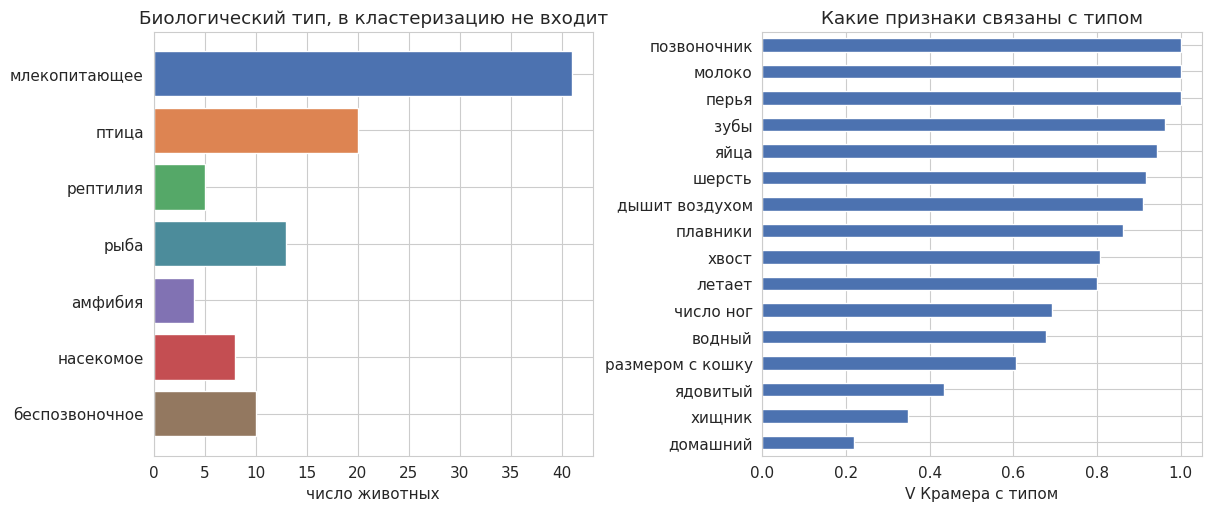

Сильнее всего с типом связаны: позвоночник, молоко, перья, зубы, яйца. Это описание файла, не отбор признаков.


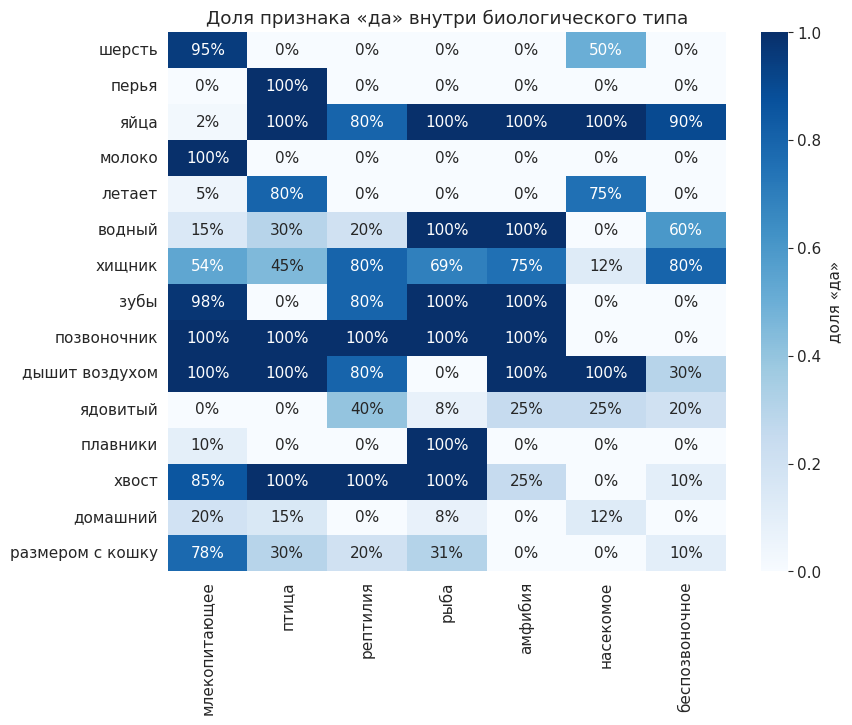

In [3]:
summary_rows = []
for column in FEATURES:
    mode = df[column].mode().iloc[0]
    if column == "legs":
        mode_text = str(int(mode))
    else:
        mode_text = "да" if int(mode) == 1 else "нет"
    summary_rows.append({
        "признак": ATTR_RU[column],
        "уровней": int(df[column].nunique()),
        "мода": mode_text,
        "доля моды": df[column].eq(mode).mean(),
    })
summary = pd.DataFrame(summary_rows)
display(summary.assign(**{"доля моды": summary["доля моды"].map(lambda v: f"{v:.1%}")}))

type_counts = df["type"].map(TYPE_RU).value_counts().reindex(TYPE_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].barh(type_counts.index[::-1], type_counts.to_numpy()[::-1], color=TYPE_COLOR[::-1])
axes[0].set_xlabel("число животных")
axes[0].set_title("Биологический тип, в кластеризацию не входит")
assoc = pd.Series({ATTR_RU[c]: cramers_v(df[c], df["type"]) for c in FEATURES}).sort_values()
assoc.plot.barh(ax=axes[1], color="#4C72B0")
axes[1].set_xlabel("V Крамера с типом")
axes[1].set_title("Какие признаки связаны с типом")
plt.show()
print(
    "Сильнее всего с типом связаны:",
    ", ".join(assoc.sort_values(ascending=False).head(5).index) + ".",
    "Это описание файла, не отбор признаков.",
)

yes_by_type = pd.DataFrame(
    {TYPE_RU[code]: df.loc[df["type"] == code, BINARY].eq(1).mean().to_numpy() for code in TYPE_RU},
    index=[ATTR_RU[c] for c in BINARY],
)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(yes_by_type, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "доля «да»"})
ax.set_title("Доля признака «да» внутри биологического типа")
ax.set_xlabel("")
plt.show()

## 3. CLOPE

Описание животного — множество элементов «признак=значение». Для кластера \(C\):

\[
S(C)=\sum_{t\in C}|t|,\qquad W(C)=\Bigl|\bigcup_{t\in C} t\Bigr|,\qquad H(C)=\frac{S(C)}{W(C)}.
\]

\(S\) — площадь, \(W\) — ширина, \(H\) — высота. У полностью одинаковых описаний ширина равна 16: на каждый признак приходится одно значение. Критерий с коэффициентом отталкивания \(r\):

\[
Profit_r=\frac{\sum_i |C_i|\cdot S(C_i)\,/\,W(C_i)^r}{\sum_i |C_i|}.
\]

Прирост от добавления транзакции \(t\):

\[
\Delta^+(C,t)=\frac{S'(N+1)}{(W')^r}-\frac{S\cdot N}{W^r}.
\]

Для пустого кластера прирост равен \(|t|^{1-r}\). Первый проход раскладывает животных, дальше каждое переносится только туда, где прирост строго больше.

Profit при разных \(r\) сравнивать нельзя: у ширины разная степень. Рабочее \(r\) — наибольшее, при котором переносы заканчиваются за 40 проходов. Тип животного в этом выборе не участвует. Значение 2,6, стоящее в узле Loginom по умолчанию, видно на том же графике.

,r,кластеров,мин. размер,Profit,грязных,сошёлся,проходов
0,1.0,2,1,45.272,1,нет,40
1,1.5,3,1,5.115,1,нет,40
2,1.8,5,1,1.577,1,нет,40
3,2.0,6,2,0.723,2,да,4
4,2.1,5,6,0.530,2,да,3
5,2.2,8,1,0.391,1,нет,40
6,2.6,11,1,0.113,1,нет,40
7,3.0,11,1,0.033,2,нет,40


Выбран r = 2.1: наибольший коэффициент, при котором переносы закончились. Тип животного в этом выборе не участвует.


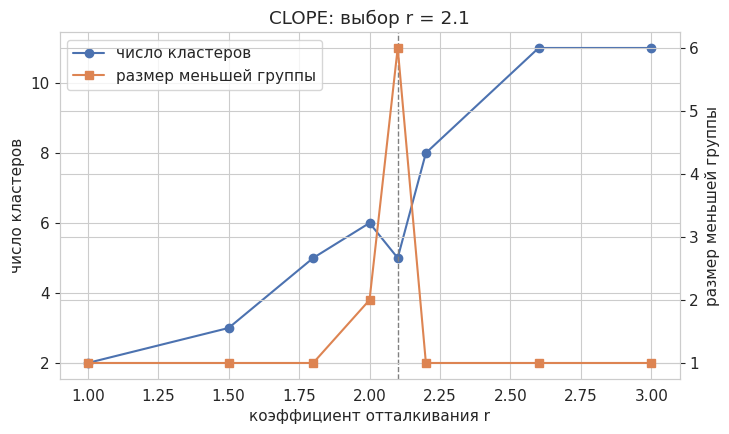

In [4]:
class Cluster:
    """Сводка кластера CLOPE: N, S, W и частоты элементов."""

    def __init__(self):
        self.n = 0
        self.s = 0
        self.w = 0
        self.occ = Counter()

    def add(self, items):
        self.n += 1
        self.s += len(items)
        for item in items:
            if self.occ[item] == 0:
                self.w += 1
            self.occ[item] += 1

    def remove(self, items):
        self.n -= 1
        self.s -= len(items)
        for item in items:
            self.occ[item] -= 1
            if self.occ[item] == 0:
                self.w -= 1
                del self.occ[item]


def delta_add(cluster, items, repulsion):
    s_new = cluster.s + len(items)
    w_new = cluster.w + sum(cluster.occ[item] == 0 for item in items)
    if cluster.n == 0:
        return s_new / (w_new ** repulsion)
    return (
        s_new * (cluster.n + 1) / (w_new ** repulsion)
        - cluster.s * cluster.n / (cluster.w ** repulsion)
    )


def best_add(items, clusters, repulsion):
    """Индекс лучшего кластера. -1 означает новый кластер."""
    best_index = -1
    best_delta = len(items) ** (1.0 - repulsion)
    for index, cluster in enumerate(clusters):
        if cluster.n == 0:
            continue
        gain = delta_add(cluster, items, repulsion)
        if gain > best_delta + 1e-12:
            best_delta = gain
            best_index = index
    return best_index


def fit_clope(data, repulsion, max_passes=40):
    clusters = []
    assign = [-1] * len(data)
    for tid, items in enumerate(data):
        index = best_add(items, clusters, repulsion)
        if index < 0:
            cluster = Cluster()
            cluster.add(items)
            clusters.append(cluster)
            assign[tid] = len(clusters) - 1
        else:
            clusters[index].add(items)
            assign[tid] = index
    passes = 1
    moved = 0
    for _ in range(max_passes - 1):
        moved = 0
        for tid, items in enumerate(data):
            current = assign[tid]
            clusters[current].remove(items)
            index = best_add(items, clusters, repulsion)
            if index < 0:
                cluster = Cluster()
                cluster.add(items)
                clusters.append(cluster)
                assign[tid] = len(clusters) - 1
                moved += 1
            else:
                clusters[index].add(items)
                assign[tid] = index
                moved += int(index != current)
        passes += 1
        if moved == 0:
            break
    alive = {}
    compact = []
    for index, cluster in enumerate(clusters):
        if cluster.n == 0:
            continue
        alive[index] = len(compact)
        compact.append(cluster)
    labels = np.array([alive[index] for index in assign], dtype=int)
    numerator = sum(cluster.s * cluster.n / (cluster.w ** repulsion) for cluster in compact)
    return labels, numerator / len(data), passes, moved == 0


def renumber_by_size(labels):
    order = pd.Series(labels).value_counts().index.tolist()
    remap = {old: new for new, old in enumerate(order, start=1)}
    return np.array([remap[value] for value in labels], dtype=int)


def partition_table(frame, labels):
    work = frame[["type"]].copy()
    work["cluster"] = labels
    rows = []
    for cluster_id, part in work.groupby("cluster"):
        counts = part["type"].value_counts()
        rows.append({
            "кластер": int(cluster_id),
            "N": len(part),
            "типов": int(counts.size),
            "большинство": TYPE_RU[int(counts.index[0])],
            "смешанный": counts.size > 1,
            "доля большинства": float(counts.iloc[0] / len(part)),
        })
    return pd.DataFrame(rows).sort_values("N", ascending=False)


stored = {}
sweep_rows = []
for repulsion in REPULSIONS:
    raw_labels, profit, passes, converged = fit_clope(transactions, repulsion)
    labels = renumber_by_size(raw_labels)
    table = partition_table(df, labels)
    stored[repulsion] = (labels, profit, passes, converged)
    sweep_rows.append({
        "r": repulsion,
        "кластеров": int(table.shape[0]),
        "мин. размер": int(table["N"].min()),
        "Profit": profit,
        "грязных": int(table["смешанный"].sum()),
        "сошёлся": converged,
        "проходов": passes,
    })
sweep = pd.DataFrame(sweep_rows)
eligible = sweep[sweep["сошёлся"]]
chosen_r = float(eligible["r"].max()) if not eligible.empty else float(sweep.loc[sweep["мин. размер"].idxmax(), "r"])

view = sweep.copy()
view["Profit"] = view["Profit"].map(lambda v: f"{v:.3f}")
view["сошёлся"] = view["сошёлся"].map(lambda v: "да" if v else "нет")
display(view)
print(
    f"Выбран r = {chosen_r}: наибольший коэффициент, при котором переносы закончились. "
    "Тип животного в этом выборе не участвует."
)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax2 = ax1.twinx()
line_k, = ax1.plot(sweep["r"], sweep["кластеров"], marker="o", color="#4C72B0", label="число кластеров")
line_n, = ax2.plot(sweep["r"], sweep["мин. размер"], marker="s", color="#DD8452", label="размер меньшей группы")
ax1.axvline(chosen_r, color="gray", ls="--", lw=1)
ax1.set_xlabel("коэффициент отталкивания r")
ax1.set_ylabel("число кластеров")
ax2.set_ylabel("размер меньшей группы")
ax1.set_title(f"CLOPE: выбор r = {chosen_r}")
ax1.legend([line_k, line_n], [line_k.get_label(), line_n.get_label()], loc="upper left")
plt.show()

CLOPE, r = 2.1: 5 кластеров, грязных 2, проходов 3, сошёлся да, Profit 0.530, чистота по типу 81.2%.
Площадь S равна 16N: у каждого животного 16 признаков.


,кластер,N,большинство,смешанный,доля большинства,W,S,H,мода ног,доля
0,1,33,млекопитающее,False,100.0%,21,528,25.1,4,32.7%
1,2,27,беспозвоночное,True,37.0%,32,432,13.5,6,26.7%
2,3,20,птица,False,100.0%,21,320,15.2,2,19.8%
3,4,15,рыба,True,86.7%,23,240,10.4,0,14.9%
4,5,6,млекопитающее,False,100.0%,26,96,3.7,2,5.9%


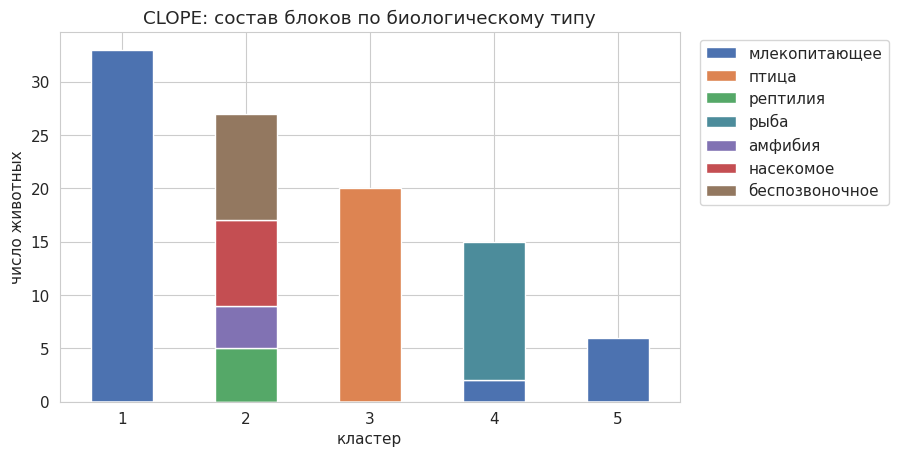

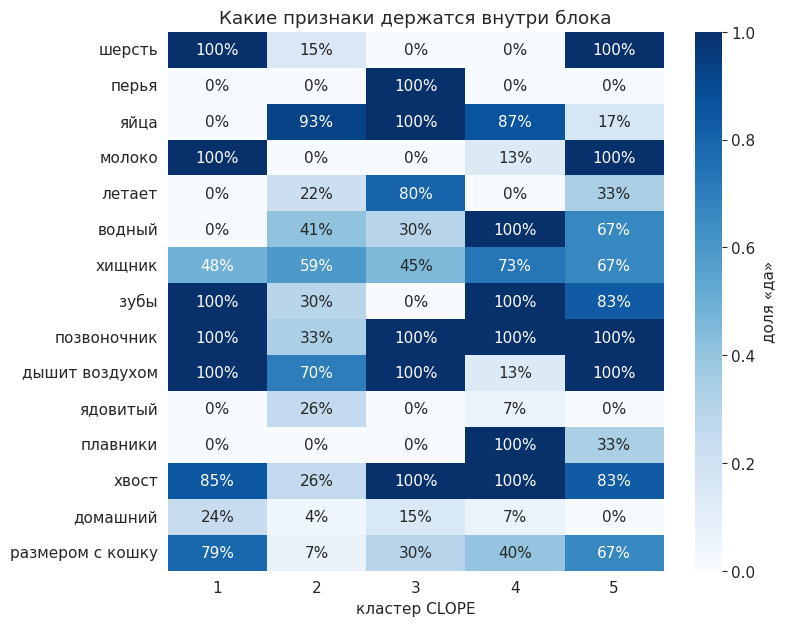

Расстояние до центра — доля признаков, не совпавших с модой блока. Для номинальных признаков это расстояние Гауэра.


,кластер,N,W,H,мода ног,среднее расстояние до моды
0,1,33,21,25.1,4,0.076
1,2,27,32,13.5,6,0.215
2,3,20,21,15.2,2,0.087
3,4,15,23,10.4,0,0.075
4,5,6,26,3.7,2,0.167


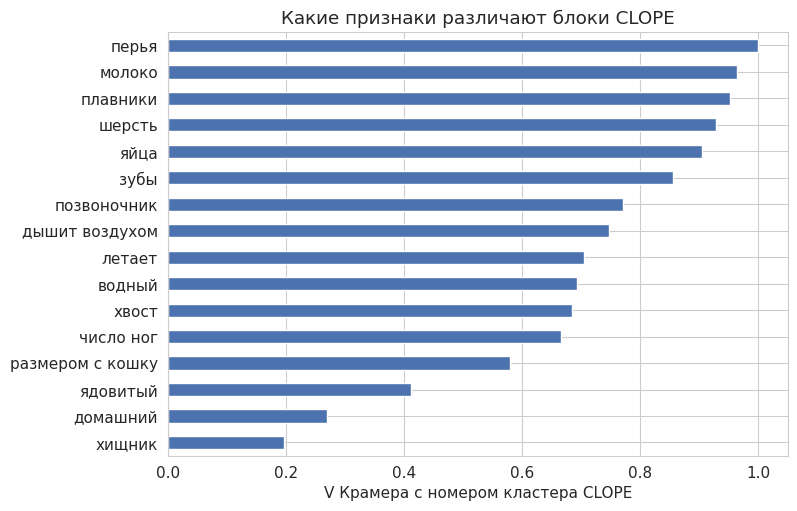

Сильнее всего блоки различают: перья, молоко, плавники, шерсть, яйца.
Состав блоков. В первой строке — позиции, которые почти постоянны внутри блока и реже встречаются в таблице в целом.
  1 (N=33, W=21, млекопитающее): молоко: да (100%); яйца: нет (100%); шерсть: да (100%); число ног: 4 (88%)
     антилопа, белка, буйвол, валлаби, волк, гепард, горилла, девочка, енот, жираф, заяц, кабан и ещё 21
  2 (N=27, W=32, смешанный, чаще всего беспозвоночное): молоко: нет (100%); размером с кошку: нет (93%); яйца: да (93%); шерсть: нет (85%)
     блоха, божья коровка, веретеница, гаттерия, жаба, краб, лягушка, лягушка, моллюск, моль, морская звезда, морская змея и ещё 15
  3 (N=20, W=21, птица): перья: да (100%); число ног: 2 (100%); зубы: нет (100%); летает: да (80%)
     водорез, воробей, ворона, голубь, гриф, жаворонок, киви, крапивник, курица, лебедь, нанду, пингвин и ещё 8
  4 (N=15, W=23, смешанный, чаще всего рыба): плавники: да (100%); число ног: 0 (100%); дышит воздухом: нет (87%); вод

In [5]:
clope_labels, profit, passes, converged = stored[chosen_r]
df["clope"] = clope_labels
clope_table = partition_table(df, clope_labels)
stat_rows = []
for cluster_id in clope_table["кластер"]:
    member = np.flatnonzero(clope_labels == cluster_id)
    occ = Counter(item for index in member for item in transactions[index])
    area = sum(len(transactions[index]) for index in member)
    leg_mode = int(df.loc[clope_labels == cluster_id, "legs"].mode().iloc[0])
    stat_rows.append({
        "кластер": int(cluster_id),
        "W": len(occ),
        "S": area,
        "H": area / len(occ),
        "мода ног": leg_mode,
    })
clope_report = clope_table.merge(pd.DataFrame(stat_rows), on="кластер")
purity = (clope_report["N"] * clope_report["доля большинства"]).sum() / len(df)
word = ru_form(clope_report.shape[0], ("кластер", "кластера", "кластеров"))
print(
    f"CLOPE, r = {chosen_r}: {clope_report.shape[0]} {word}, "
    f"грязных {int(clope_report['смешанный'].sum())}, проходов {passes}, "
    f"сошёлся {'да' if converged else 'нет'}, Profit {profit:.3f}, чистота по типу {purity:.1%}."
)
print("Площадь S равна 16N: у каждого животного 16 признаков.")
view = clope_report.copy()
view["доля"] = (view["N"] / len(df)).map(lambda v: f"{v:.1%}")
view["доля большинства"] = view["доля большинства"].map(lambda v: f"{v:.1%}")
view["H"] = view["H"].map(lambda v: f"{v:.1f}")
display(view.drop(columns="типов"))

stack = pd.crosstab(
    pd.Series(clope_labels, name="кластер"),
    df["type"].map(TYPE_RU),
).reindex(columns=TYPE_ORDER).fillna(0)
fig, ax = plt.subplots(figsize=(8, 4.8))
stack.plot.bar(stacked=True, color=TYPE_COLOR, ax=ax, rot=0)
ax.set_xlabel("кластер")
ax.set_ylabel("число животных")
ax.set_title("CLOPE: состав блоков по биологическому типу")
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

yes_rate = pd.DataFrame(index=[ATTR_RU[c] for c in BINARY])
for cluster_id in clope_report["кластер"]:
    part = df.loc[clope_labels == cluster_id, BINARY]
    yes_rate[int(cluster_id)] = part.eq(1).mean().to_numpy()
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(yes_rate, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "доля «да»"})
ax.set_xlabel("кластер CLOPE")
ax.set_title("Какие признаки держатся внутри блока")
plt.show()


def attribute_association(frame, labels):
    scores = {ATTR_RU[column]: cramers_v(frame[column], labels) for column in FEATURES}
    return pd.Series(scores).sort_values(ascending=False)


def mode_distance(codes, labels):
    """Среднее расстояние Гауэра от животного до моды своего кластера."""
    distances = np.empty(len(codes))
    modes = {}
    for cluster_id in np.unique(labels):
        mask = labels == cluster_id
        part = codes[mask]
        mode = np.empty(part.shape[1], dtype=part.dtype)
        for feature in range(part.shape[1]):
            values, counts = np.unique(part[:, feature], return_counts=True)
            mode[feature] = values[counts.argmax()]
        modes[int(cluster_id)] = mode
        distances[mask] = (part != mode).mean(axis=1)
    return distances, modes


code_maps, inverse_maps = {}, {}
codes = np.empty((len(df), len(FEATURES)), dtype=np.int16)
for j, column in enumerate(FEATURES):
    levels = sorted(df[column].unique(), key=lambda v: int(v))
    code_maps[column] = {level: i for i, level in enumerate(levels)}
    inverse_maps[column] = {i: level for level, i in code_maps[column].items()}
    codes[:, j] = df[column].map(code_maps[column]).to_numpy()

clope_gower, clope_modes = mode_distance(codes, clope_labels)
clope_report = clope_report.merge(
    pd.DataFrame({
        "кластер": list(clope_modes),
        "среднее расстояние до моды": [float(clope_gower[clope_labels == cluster_id].mean()) for cluster_id in clope_modes],
    }),
    on="кластер",
)
print("Расстояние до центра — доля признаков, не совпавших с модой блока. Для номинальных признаков это расстояние Гауэра.")
display(clope_report[["кластер", "N", "W", "H", "мода ног", "среднее расстояние до моды"]].assign(
    H=lambda t: t["H"].map(lambda v: f"{v:.1f}"),
    **{"среднее расстояние до моды": lambda t: t["среднее расстояние до моды"].map(lambda v: f"{v:.3f}")},
))

clope_assoc = attribute_association(df, clope_labels)
fig, ax = plt.subplots(figsize=(8, 5.5))
clope_assoc.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("V Крамера с номером кластера CLOPE")
ax.set_title("Какие признаки различают блоки CLOPE")
plt.show()
print("Сильнее всего блоки различают:", ", ".join(clope_assoc.head(5).index) + ".")


def value_text(column, level):
    if column == "legs":
        return str(int(level))
    return "да" if int(level) == 1 else "нет"


def distinctive_lines(frame, labels, cluster_id, limit=4):
    mask = labels == cluster_id
    found = []
    for column in FEATURES:
        local = frame.loc[mask, column].value_counts(normalize=True)
        overall = frame[column].value_counts(normalize=True)
        level = local.index[0]
        share = float(local.iloc[0])
        gap = share - float(overall.get(level, 0.0))
        if share >= 0.8 and gap >= 0.15:
            found.append((gap, ATTR_RU[column], value_text(column, level), share))
    found.sort(reverse=True)
    return [f"{name}: {value} ({share:.0%})" for _, name, value, share in found[:limit]]


def member_line(labels, cluster_id):
    names = df.loc[labels == cluster_id, "name"].map(animal_ru)
    ordered = sorted(names)
    if len(ordered) <= 16:
        return ", ".join(ordered)
    return ", ".join(ordered[:12]) + f" и ещё {len(ordered) - 12}"


print("Состав блоков. В первой строке — позиции, которые почти постоянны внутри блока и реже встречаются в таблице в целом.")
for row in clope_report.itertuples():
    traits = distinctive_lines(df, clope_labels, row.кластер)
    kind = row.большинство if not row.смешанный else f"смешанный, чаще всего {row.большинство}"
    text = "; ".join(traits) if traits else "нет признака, который держался бы у 80% блока и выделял его на фоне таблицы"
    print(f"  {row.кластер} (N={row.N}, W={row.W}, {kind}): {text}")
    print(f"     {member_line(clope_labels, row.кластер)}")

## 4. Второй метод: k-modes и расстояние Гауэра

Для номинального признака расстояние Гауэра между двумя животными — доля несовпавших признаков:

\[
d(x,y)=\frac{1}{p}\sum_{j=1}^{p}[x_j\neq y_j].
\]

У всех 16 признаков один и тот же вес \(1/p\). Число ног сравнивается как категория: 4 и 2 — разные значения, а не «близкие числа». Среднего у «да / нет» нет, поэтому центр кластера в k-modes — мода. Число групп \(k\) выбирается по силуэту на полной матрице расстояний Гауэра. Тип в выборе \(k\) не участвует. Рядом считается решение с тем же числом групп, что у CLOPE.

,k,силуэт,среднее расстояние до моды
0,2,0.460,0.204
1,3,0.514,0.145
2,4,0.557,0.116
3,5,0.567,0.103
4,6,0.462,0.095
5,7,0.457,0.089
6,8,0.411,0.077


Максимум силуэта при k = 5. Число кластеров CLOPE: 5.


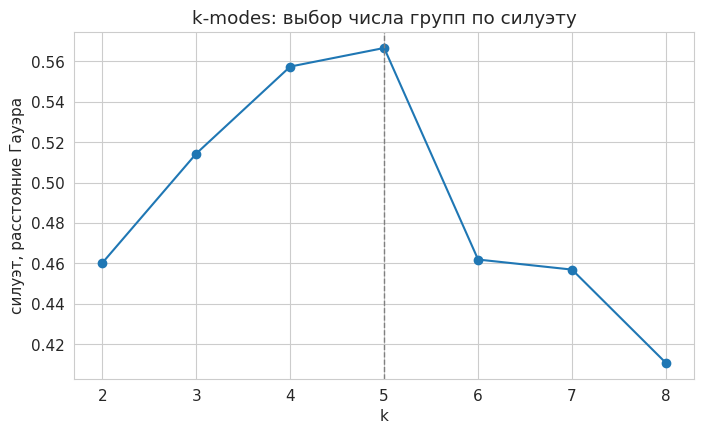

k-modes, k = 5: среднее расстояние Гауэра до моды 0.103, грязных кластеров 5, чистота 88.1%.


,кластер,N,типов,большинство,смешанный,доля большинства,среднее расстояние до моды
0,1,42,2,млекопитающее,True,97.6%,0.107
1,2,21,2,птица,True,95.2%,0.095
2,3,17,3,рыба,True,76.5%,0.085
3,4,11,2,насекомое,True,72.7%,0.114
4,5,10,2,беспозвоночное,True,70.0%,0.125


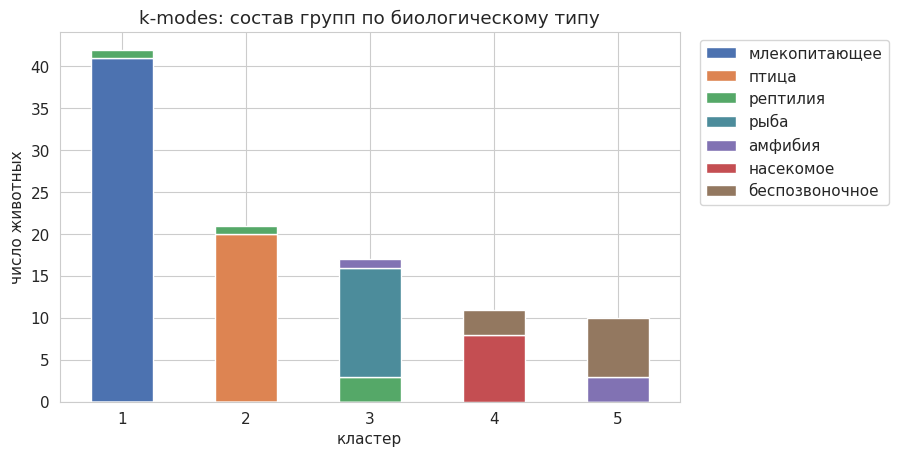

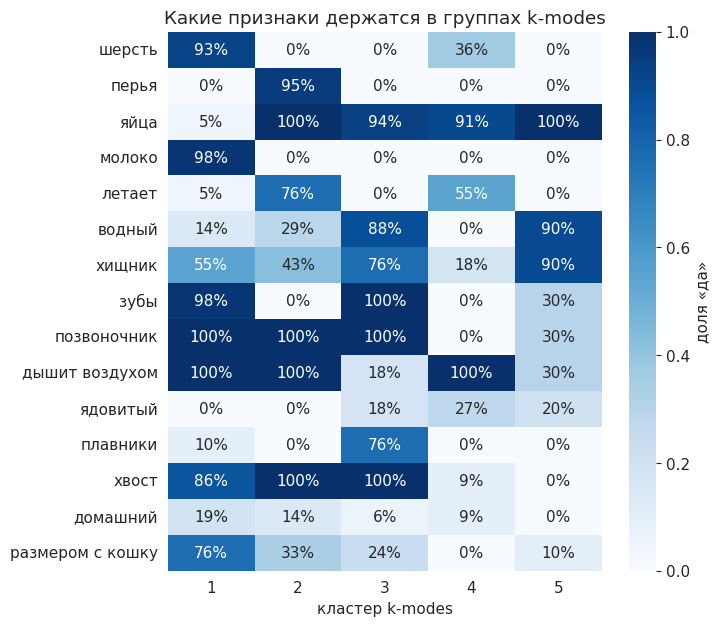

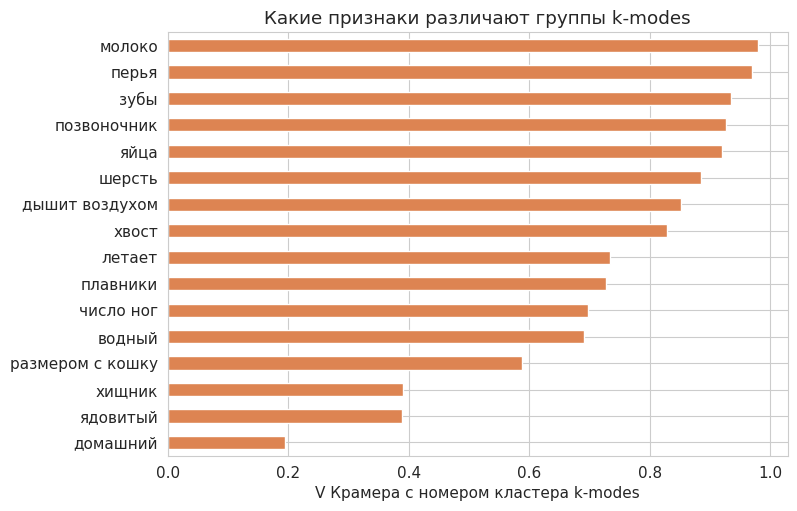

Сильнее всего группы k-modes различают: молоко, перья, зубы, позвоночник, яйца.
Состав групп k-modes:
  1 (N=42, смешанный, чаще всего млекопитающее): молоко: да (98%); яйца: нет (95%); шерсть: да (93%); зубы: да (98%)
     антилопа, белка, буйвол, валлаби, волк, гаттерия, гепард, горилла, девочка, дельфин, енот, жираф и ещё 30
  2 (N=21, смешанный, чаще всего птица): перья: да (95%); число ног: 2 (95%); зубы: нет (100%); шерсть: нет (100%)
     водорез, воробей, ворона, голубь, гриф, жаворонок, киви, крапивник, курица, лебедь, нанду, пингвин и ещё 9
  3 (N=17, смешанный, чаще всего рыба): число ног: 0 (94%); дышит воздухом: нет (82%); водный: да (88%); шерсть: нет (100%)
     веретеница, голавль, карп, катран, морская змея, морской конёк, морской язык, окунь, пикша, пиранья, сельдь, скат и ещё 5
  4 (N=11, смешанный, чаще всего насекомое): позвоночник: нет (100%); хвост: нет (91%); зубы: нет (100%); размером с кошку: нет (100%)
     блоха, божья коровка, моль, мошка, муха, оса, пчела,

,N,молоко,перья,зубы,позвоночник,яйца,шерсть,дышит воздухом,хвост
кластер,,,,,,,,,
1,42,да,нет,да,да,нет,да,да,да
2,21,нет,да,нет,да,да,нет,да,да
3,17,нет,нет,да,да,да,нет,нет,да
4,11,нет,нет,нет,нет,да,нет,да,нет
5,10,нет,нет,нет,нет,да,нет,нет,нет


In [6]:
def gower_to_modes(data, modes):
    return (data[:, None, :] != modes[None, :, :]).mean(axis=2)


def fit_kmodes(data, k, n_init=20, max_iter=40, seed=42):
    rng = np.random.default_rng(seed)
    n_rows = data.shape[0]
    best = None
    for _init in range(n_init):
        modes = data[rng.choice(n_rows, size=k, replace=False)].copy()
        labels = np.full(n_rows, -1, dtype=int)
        for _ in range(max_iter):
            distances = gower_to_modes(data, modes)
            new_labels = distances.argmin(axis=1).astype(int)
            for cluster_id in range(k):
                if np.any(new_labels == cluster_id):
                    continue
                sizes = np.bincount(new_labels, minlength=k)
                donors = np.flatnonzero(sizes > 1)
                if len(donors) == 0:
                    break
                pool = np.flatnonzero(np.isin(new_labels, donors))
                far = pool[distances[pool].min(axis=1).argmax()]
                new_labels[far] = cluster_id
            new_modes = modes.copy()
            for cluster_id in range(k):
                part = data[new_labels == cluster_id]
                if len(part) == 0:
                    continue
                for feature in range(data.shape[1]):
                    values, counts = np.unique(part[:, feature], return_counts=True)
                    new_modes[cluster_id, feature] = values[counts.argmax()]
            stable = np.array_equal(new_labels, labels)
            labels = new_labels
            modes = new_modes
            if stable:
                break
        cost = float(gower_to_modes(data, modes)[np.arange(n_rows), labels].mean())
        if best is None or cost < best[0]:
            best = (cost, labels.copy())
    labels = renumber_by_size(best[1])
    distances, modes = mode_distance(data, labels)
    return labels, modes, float(distances.mean())


mismatch = np.zeros((len(codes), len(codes)))
for feature in range(codes.shape[1]):
    mismatch += codes[:, feature, None] != codes[None, :, feature]
mismatch /= codes.shape[1]


def silhouette_of(labels):
    if len(np.unique(labels)) < 2:
        return np.nan
    return float(silhouette_score(mismatch, labels, metric="precomputed"))


k_candidates = list(range(2, 9))
matched_k = int(clope_report.shape[0])
if matched_k not in k_candidates:
    k_candidates.append(matched_k)
k_rows = []
k_store = {}
for k in k_candidates:
    labels, modes, mean_distance = fit_kmodes(codes, k)
    k_store[k] = (labels, modes, mean_distance)
    k_rows.append({"k": k, "силуэт": silhouette_of(labels), "среднее расстояние до моды": mean_distance})
k_tbl = pd.DataFrame(k_rows).sort_values("k")
display(k_tbl.assign(**{
    "силуэт": k_tbl["силуэт"].map(lambda v: f"{v:.3f}"),
    "среднее расстояние до моды": k_tbl["среднее расстояние до моды"].map(lambda v: f"{v:.3f}"),
}))
best_k = int(k_tbl.sort_values(["силуэт", "k"], ascending=[False, True]).iloc[0]["k"])
print(f"Максимум силуэта при k = {best_k}. Число кластеров CLOPE: {matched_k}.")

fig, ax = plt.subplots(figsize=(8, 4.5))
shown = k_tbl[k_tbl["k"] <= 8]
ax.plot(shown["k"], shown["силуэт"], marker="o")
ax.axvline(best_k, color="gray", ls="--", lw=1)
ax.set_xlabel("k")
ax.set_ylabel("силуэт, расстояние Гауэра")
ax.set_title("k-modes: выбор числа групп по силуэту")
plt.show()

kmodes_labels, kmodes_modes, kmodes_distance = k_store[best_k]
df["kmodes"] = kmodes_labels
kmodes_table = partition_table(df, kmodes_labels)
kmodes_gower, _ = mode_distance(codes, kmodes_labels)
kmodes_table["среднее расстояние до моды"] = [
    float(kmodes_gower[kmodes_labels == cluster_id].mean()) for cluster_id in kmodes_table["кластер"]
]
kmodes_purity = (kmodes_table["N"] * kmodes_table["доля большинства"]).sum() / len(df)
print(
    f"k-modes, k = {best_k}: среднее расстояние Гауэра до моды {kmodes_distance:.3f}, "
    f"грязных кластеров {int(kmodes_table['смешанный'].sum())}, чистота {kmodes_purity:.1%}."
)
view = kmodes_table.copy()
view["доля большинства"] = view["доля большинства"].map(lambda v: f"{v:.1%}")
view["среднее расстояние до моды"] = view["среднее расстояние до моды"].map(lambda v: f"{v:.3f}")
display(view)

stack = pd.crosstab(
    pd.Series(kmodes_labels, name="кластер"),
    df["type"].map(TYPE_RU),
).reindex(columns=TYPE_ORDER).fillna(0)
fig, ax = plt.subplots(figsize=(8, 4.8))
stack.plot.bar(stacked=True, color=TYPE_COLOR, ax=ax, rot=0)
ax.set_xlabel("кластер")
ax.set_ylabel("число животных")
ax.set_title("k-modes: состав групп по биологическому типу")
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

kmodes_yes = pd.DataFrame(index=[ATTR_RU[c] for c in BINARY])
for cluster_id in kmodes_table["кластер"]:
    part = df.loc[kmodes_labels == cluster_id, BINARY]
    kmodes_yes[int(cluster_id)] = part.eq(1).mean().to_numpy()
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(kmodes_yes, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "доля «да»"})
ax.set_xlabel("кластер k-modes")
ax.set_title("Какие признаки держатся в группах k-modes")
plt.show()

kmodes_assoc = attribute_association(df, kmodes_labels)
fig, ax = plt.subplots(figsize=(8, 5.5))
kmodes_assoc.sort_values().plot.barh(ax=ax, color="#DD8452")
ax.set_xlabel("V Крамера с номером кластера k-modes")
ax.set_title("Какие признаки различают группы k-modes")
plt.show()
print("Сильнее всего группы k-modes различают:", ", ".join(kmodes_assoc.head(5).index) + ".")
print("Состав групп k-modes:")
for row in kmodes_table.itertuples():
    traits = distinctive_lines(df, kmodes_labels, row.кластер)
    kind = row.большинство if not row.смешанный else f"смешанный, чаще всего {row.большинство}"
    text = "; ".join(traits) if traits else "нет признака с порогом 80%"
    print(f"  {row.кластер} (N={row.N}, {kind}): {text}")
    print(f"     {member_line(kmodes_labels, row.кластер)}")

print("Моды k-modes по признакам, которые сильнее всего связаны с разбиением:")
center_attrs = kmodes_assoc.head(8).index.tolist()
mode_rows = []
for cluster_id, mode in sorted(kmodes_modes.items()):
    row = {"кластер": cluster_id, "N": int((kmodes_labels == cluster_id).sum())}
    for j, column in enumerate(FEATURES):
        level = inverse_maps[column][int(mode[j])]
        row[ATTR_RU[column]] = value_text(column, level)
    mode_rows.append(row)
display(pd.DataFrame(mode_rows).set_index("кластер")[["N"] + center_attrs])

## 5. Сравнение

CLOPE само набирает число групп через коэффициент отталкивания. k-modes получает число групп от силуэта. Если эти числа расходятся, рядом считается ещё одно k-modes с тем же числом групп, что у CLOPE. Согласованность разбиений — ARI и нормированная взаимная информация. Чистота по биологическому типу — внешняя проверка: эта колонка в признаки не входила. Расстояние до центра у обоих методов — среднее расстояние Гауэра до моды кластера.

In [7]:
matched_labels = k_store[matched_k][0]
matched_table = partition_table(df, matched_labels)
matched_gower = mode_distance(codes, matched_labels)[0]
matched_purity = (matched_table["N"] * matched_table["доля большинства"]).sum() / len(df)
scores = pd.DataFrame([
    {
        "разбиение": f"CLOPE, r={chosen_r}",
        "k": int(clope_report.shape[0]),
        "грязных": int(clope_report["смешанный"].sum()),
        "чистота": purity,
        "среднее расстояние до моды": float(clope_gower.mean()),
    },
    {
        "разбиение": f"k-modes, силуэт k={best_k}",
        "k": best_k,
        "грязных": int(kmodes_table["смешанный"].sum()),
        "чистота": kmodes_purity,
        "среднее расстояние до моды": float(kmodes_gower.mean()),
    },
])
if best_k != matched_k:
    scores.loc[len(scores)] = {
        "разбиение": f"k-modes, k={matched_k} как у CLOPE",
        "k": matched_k,
        "грязных": int(matched_table["смешанный"].sum()),
        "чистота": matched_purity,
        "среднее расстояние до моды": float(matched_gower.mean()),
    }
display(scores.assign(**{
    "чистота": scores["чистота"].map(lambda v: f"{v:.1%}"),
    "среднее расстояние до моды": scores["среднее расстояние до моды"].map(lambda v: f"{v:.3f}"),
}))

agreement = pd.DataFrame([
    {
        "пара": "CLOPE и k-modes",
        "ARI": adjusted_rand_score(clope_labels, kmodes_labels),
        "NMI": normalized_mutual_info_score(clope_labels, kmodes_labels),
    },
    {
        "пара": "CLOPE и биологический тип",
        "ARI": adjusted_rand_score(clope_labels, df["type"]),
        "NMI": normalized_mutual_info_score(clope_labels, df["type"]),
    },
    {
        "пара": "k-modes по силуэту и биологический тип",
        "ARI": adjusted_rand_score(kmodes_labels, df["type"]),
        "NMI": normalized_mutual_info_score(kmodes_labels, df["type"]),
    },
])
if best_k != matched_k:
    agreement.loc[len(agreement)] = {
        "пара": f"CLOPE и k-modes при k={matched_k}",
        "ARI": adjusted_rand_score(clope_labels, matched_labels),
        "NMI": normalized_mutual_info_score(clope_labels, matched_labels),
    }
display(agreement.round(3))

top_clope = set(clope_assoc.head(5).index)
top_kmodes = set(kmodes_assoc.head(5).index)
shared = ", ".join(sorted(top_clope & top_kmodes)) or "нет"
print("Общие признаки в пятёрке самых связанных с разбиением:", shared)
print("Только CLOPE:", ", ".join(sorted(top_clope - top_kmodes)) or "нет")
print("Только k-modes:", ", ".join(sorted(top_kmodes - top_clope)) or "нет")

same_k_ari = adjusted_rand_score(clope_labels, matched_labels)
pure_n = int((~clope_report["смешанный"]).sum())
print(
    f"CLOPE при r = {chosen_r} делит таблицу на {int(clope_report.shape[0])} "
    f"{ru_form(clope_report.shape[0], ('кластер', 'кластера', 'кластеров'))}, "
    f"из них однородных по типу {pure_n}. Чистота {purity:.1%}, "
    f"среднее расстояние до моды {float(clope_gower.mean()):.3f}."
)
print(
    f"k-modes по силуэту останавливается на k = {best_k}, чистота {kmodes_purity:.1%}, "
    f"среднее расстояние до моды {float(kmodes_gower.mean()):.3f}."
)
ari_pair = adjusted_rand_score(clope_labels, kmodes_labels)
print(f"ARI разбиений CLOPE и k-modes равен {ari_pair:.3f}. Общие опоры двух методов: {shared}.")
if best_k != matched_k:
    print(
        f"При k = {matched_k} у k-modes чистота {matched_purity:.1%} "
        f"и среднее расстояние до моды {float(matched_gower.mean()):.3f}, "
        f"ARI с CLOPE равен {same_k_ari:.3f}."
    )

result = df[["transaction_id", "name", "type"]].copy()
result["животное"] = result["name"].map(animal_ru)
result["тип"] = result["type"].map(TYPE_RU)
result["clope"] = clope_labels
result["расстояние до моды CLOPE"] = clope_gower
result["kmodes"] = kmodes_labels
result["расстояние до моды k-modes"] = kmodes_gower
result.drop(columns=["name", "type"]).to_csv("animals_clusters.csv", index=False)
print("Сохранены номера кластеров и расстояния до моды: animals_clusters.csv")

,разбиение,k,грязных,чистота,среднее расстояние до моды
0,"CLOPE, r=2.1",5,2,81.2%,0.121
1,"k-modes, силуэт k=5",5,5,88.1%,0.103


,пара,ARI,NMI
0,CLOPE и k-modes,0.649,0.723
1,CLOPE и биологический тип,0.689,0.791
2,k-modes по силуэту и биологический тип,0.898,0.854


Общие признаки в пятёрке самых связанных с разбиением: молоко, перья, яйца
Только CLOPE: плавники, шерсть
Только k-modes: зубы, позвоночник
CLOPE при r = 2.1 делит таблицу на 5 кластеров, из них однородных по типу 3. Чистота 81.2%, среднее расстояние до моды 0.121.
k-modes по силуэту останавливается на k = 5, чистота 88.1%, среднее расстояние до моды 0.103.
ARI разбиений CLOPE и k-modes равен 0.649. Общие опоры двух методов: молоко, перья, яйца.
Сохранены номера кластеров и расстояния до моды: animals_clusters.csv
